# 1. 네이버 뉴스 시각화

In [1]:
!pip install dotenv wordcloud


   -------------------------- ------------- 2/3 [wordcloud]
   ---------------------------------------- 3/3 [wordcloud]



## 1.1 네이버 검색 API 호출 및 검색 결과 확인
- 네이버 API 활용
    - API(Application Programming Interface): 두 소프트웨어가 서로 통신할 수 있게 해주는 메커니즘과 해당 기능을 사용할 수 있게하는 프로그램
    - 라이브러리와 차이점: 라이브러리는 특정 기능을 구현하기 위한 코드의 집합. 내부 코드를 이해하고 사용해야하지만, API는 통신이 가능한 상황에서 간단한 명령으로 필요한 기능들을 상대적으로 쉽게 구현할 수 있게 지원 -> 사용하기 수월(단, PAI는 비용이 드는 경우가 많음)
    - 뉴스, 백과사전, 블로그, 쇼핑, 웹 문서, 전문지식, 지식IN, 책, 카페 등 분야별로 네이버 검색 결과를 JSON형태로 반환하는 기능을 지원(검색 API의 하루 호출 한도는 25,000회)
        - JSON: JavaScript Object Notaion으로, JS객체 문법을 따르는 텍스트 기반의 데이터 포맷으로 여러개의 딕셔너리들이 계층적으로 분포하는 형태이며 인간이 읽고 쓰기 쉽고, 기계가 구문을 분석하기 쉽도록 경량화된 데이터 교환 형식
        - 다른 프로그래밍 언어에서도 많이 사용되며, 파이썬에서는 JSON을 딕셔너리로 변환하여 사용(단, JSON 형식은 반드시 ""(큰따옴표)로 묶어야 함
    - https://developers.naver.com/main/
        - Application -> 내 어플리케이션 -> 사용 API는 "검색"은 필수로 선택 -> 비로그인 오픈 API는 웹 선택 후 https://my_news_crawler.com 으로 설정 -> Client ID와 Secret 복사
        - Client ID와 Secret을 env파일에 저장 (추후 streamlit 개발 시 환경변수를 올려서 사용할 예정)
            - 환경변수: 컴퓨터 프로세스가 실행되는 환경에 영향을 주는 동적인 key-value 쌍의 정보 집합으로, 프로그램이 특정 파일이나 경로를 찾거나 시스템 설정을 유연하게 참조할 수 있도록 돕는 시스템 변수 
        - Products -> 서비스 API -> 검색 -> 개발 가이드 보기 -> 뉴스 -> 요청 URL의 JSON 포맷 선택
        - 파라미터
            - query: str, 필수, 검색어로 UTF-8로 인코딩 돼야 함
            - display: int, 필수아님, 한 번에 표시할 검색 결과 개수 (기본값: 10, 최댓값: 100)
            - start: int, 필수 아님, 검색어 시작 위치 (기본값: 1, 최댓값 100)
            - sort: str, 필수 아님, 검색 결과 정렬 방법 (sim: 정확도순으로 내림차순 정렬, date: 날짜순으로 내림차순 정렬)












In [17]:
import requests
import json
import os
from dotenv import load_dotenv

load_dotenv()

client_id = os.getenv('NAVER_CLIENT_ID')
client_secret = os.getenv('NAVER_CLIENT_SECRET')

query = '부동산'
display = 100
start = 1


headers = {'X-Naver-Client-Id':client_id, 'X-Naver-Client-Secret': client_secret}
params = {'query':query, 'dispaly':display, 'start':start}

url = 'https://openapi.naver.com/v1/search/news.json'

response = requests.get(url, headers=headers, params=params)

news_json = json.loads(response.text)

# print(type(new_json))

# new_json

print('new_json 자료형', type(news_json))
print('new_json key 종류', news_json.keys())
print('new_json 개수', len(news_json['items']))
print('첫 번째 뉴스 key 종류', news_json['items'][0].keys())
print()

cnt = 1

for news in news_json['items']:
    if 'n.news.naver' in news.get('link'):
        print(news.keys())
        print('count', cnt)
        print('title', news.get('title'))
        print('link', news.get('link'))
        print('orginallink', news.get('originallink'))
        print('description', news.get('description'))
        print()
        
        cnt += 1
        
        break

new_json 자료형 <class 'dict'>
new_json key 종류 dict_keys(['lastBuildDate', 'total', 'start', 'display', 'items'])
new_json 개수 10
첫 번째 뉴스 key 종류 dict_keys(['title', 'originallink', 'link', 'description', 'pubDate'])

dict_keys(['title', 'originallink', 'link', 'description', 'pubDate'])
count 1
title 수출 덕에 5% 성장목표 사수한 中, '내수·<b>부동산</b>' 여전히 난제
link https://n.news.naver.com/mnews/article/008/0005306388?sid=101
orginallink https://www.mt.co.kr/world/2026/01/19/2026011912485229792
description 하지만 각종 부양책에도 내수와 <b>부동산</b> 경기 둔화가 여전했고 이 때문에 하반기 내내 성장속도가 떨어져... 이는 중국 경제의 큰 부분을 차지한 내수와 <b>부동산</b> 시장 부진 탓이다. 소비의 핵심 지표인 소매판매는... 



# 워드클라우드
## 1.2 워드클라우드 실습 

- random_state: 
    - WorldCloud는 다음을 랜덤하게 결정하기 때문에 같은 데이터라도 실행할 때마다 단어 위치/모양이 달라질 수 있음 
        - 단어의 배치
        - 단어의 회전 여부
        - 단어의 배치 순서
        - 일부 스타일 요소 
    - 역할
        - 난수 생성기의 시드(seed)를 고정하여 결과이미지를 항상 동일하게 해줌   
            - seed: 난수를 만들기 위한 시작 번호(기준값)로, 컴퓨터는 완전히 랜덤한 숫자를 만들지 못하기 때문에 대신 알고리즘으로 랜덤처럼 보이는 숫자를 만들어서 동일한 seed를 사용하면 동일한 난수 결과를 재현하도록 함
            - 난수: 옉측할 수 없고 규칙이 없는 것처럼 보이는 숫자 (ex: 주사위 결과, 동전 던지기)
        - 즉, 결과 재현성 확보용으로 쓰임 

2


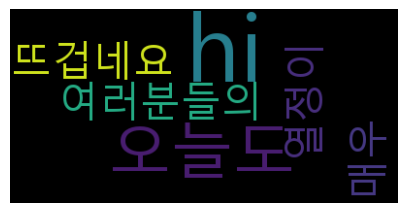

In [30]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import random

print(random.randint(1,10))
wc = WordCloud(
    font_path = 'C:/Windows/Fonts/malgun.ttf',
    background_color = 'black',
    max_words = 10,
    random_state = 99,
    stopwords = {'등', '있다', '및', '수', '이'}
)

text = 'hi hi hi 오늘도 여러분들의 열정이 매우 뜨겁네요 !! '

fig = plt.figure(figsize=(5,5))

# generate: 문자열에서 단어의 빈도(띄워쓰기 기준)를 자동 계산하여 워드클라우드 생성
# imgshow: 이미지 또는 2차원 배열을 화면에 표시하는 함수로, 위에서 생성한 워드클라우드 이미지를 figure에 표시해줌
# interpolation: 이미지를 확대/축소할 때 필셀 사이를 어떻게 채울지 결정하는 방식 
# - 원본 이미진는 픽셀단위인데 화면에 그릴 때 크기가 달라지면 픽셀 사이를 어떻게 보간(interpolate)할지가 필요 
# - bilinear: 주변 4개 픽셀값을 이용해 부드럽게 보간(두 값 사이의 빈 칸을 추정해서 채우는 것) -> 계단 현상 감소
 
wc.generate(text)
wc.generate(text)
plt.imshow(wc, interpolation='bilinear')

plt.axis('off')
plt.show()

## 2.3 Streamlit으로 뉴스 크롤링 시각화



In [52]:
%%writefile my_web/08_navernews_dashboard.py

from bs4 import BeautifulSoup
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from PIL import Image
import streamlit as st
from dotenv import load_dotenv
import os

load_dotenv()
client_id = os.getenv('NAVER_CLIENT_ID')
client_secret = os.getenv('NAVER_CLIENT_SECRET')

# 함수 설정: 네이버 검색 API를 활용한 뉴스 검색 결과를 반환해주는 함수
def get_requests(query, display, start):
    headers = {'X-Naver-Client-Id':client_id, 'X-Naver-Client-Secret': client_secret}
    
    params = {'query':query, 'dispaly':display, 'start':start}

    url = 'https://openapi.naver.com/v1/search/news.json'

    response = requests.get(url, headers=headers, params=params)

    news_json = json.loads(response.text)
    
    return news_json['items']


# 워드 클라우드 시각화 함수
def wc_chart(corpus, back_mask, max_words, emp):
    if back_mask == '타원':
        img = Image.open('../../data/background_1.png')
    elif back_mask == '말풍선':
        img = Image.open('../../data/background_2.png')
    else:
        img = Image.open('../../data/background_3.png')
    
    my_mask = np.array(img)
    
    wc = WordCloud(
        font_path = 'C:/Windows/Fonts/malgun.ttf',
        background_color = 'black',
        max_words = max_words,
        random_state = 99,
        stopwords = ['등', '있다', '및', '수', '이', 'the', 'a', 'of', 'to', 'in', 'and', 'said', 'was', 'by'],
        mask = my_mask
    )
    wc.generate(corpus) #corpus 말주머니?
    
    fig = plt.figure(figsize=(10,10))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    st.pyplot(fig)
    emp.success(':orange[**워드 클라우드 이미지 생성 완료**]', icon='✅')
    
# 세선 설정

if 'client_id' not in st.session_state:
    st.session_state['client_id'] = client_id
    
if 'client_secret' not in st.session_state:
    st.session_state['client_secret'] = client_secret

    
# 사이드바 설정

with st.sidebar.form(key='form1', clear_on_submit=False):
    st.header('네이버 API 설정')
    client_id = st.text_input('Client ID:', value=st.session_state['client_id'])
    client_secret = st.text_input('Client Secret:', value=st.session_state['client_secret'])
    
    if st.form_submit_button(label='OK'):
        st.session_state['client_id'] = client_id
        st.session_state['client_secret'] = client_secret
        st.write('설정 완료!')
        
# 메인화면 설정
chart_emp = st.empty()

try:
    with st.form(key='Search', clear_on_submit=False):
        search_keyword = st.selectbox('키워드:', ['경제', '정치', '사회', '국제', '연예', 'IT', '문화'])
        data_amount = st.slider('분량(1당 100개)', min_value=1, max_value=5, value=1, step=1)
        back_mask = st.radio('워드 클라우드 출력 형태:', ['기본', '타원', '말풍선', '하트'], horizontal=True)
        
        if st.form_submit_button('출력'):
            chart_emp.info(':red[데이터 가져오는 중...]')
            
            # 데이터 수집
            corpus = ''# 수집된 문자열이 담길 변수 선언
            items = []
            
            for i in range(data_amount):
                items.extend(get_requests(search_keyword, 100, 100*i+1))
            
            for item in items:
                if 'n.news.naver' in item['link']:
                    news_url = item['link']
                    response = requests.get(news_url)
                    soup = BeautifulSoup(response.text, 'lxml')
                    body_area = soup.select_one('#dic_area')
                    if body_area:
                        news_text_list = body_area.find_all(string=True, recursive=False)
                        news_text = "".join(text.strip() for text in news_text_list)
                        corpus += news_text + " "
            st.write(f'수집된 corpus 글자수: {len(corpus)}')
        
        
            # 워드 클라우드 생성
            if len(corpus) >= 100: # corpus 길이가 너무 짧으면 워드클라우드의 출력이 적절하지 않기 때문에 조건 설정
                chart_emp.info(':red[이미지 생성 중...]')
                wc_chart(corpus, back_mask, 70, chart_emp)
            else:
                chart_emp.error(':red[워드클라우드를 생성하기에 데이터가 충분하지 않습니다.]')
except Exception as e:
    st.write(e)
    chart_emp.error('ID와 Secret를 입력해주세요.')

Overwriting my_web/08_navernews_dashboard.py
